# Session 5 – Decision Tree Classifier: Titanic Survival

**Goal:** Train a Decision Tree using the actual Titanic passenger training dataset and visualize the learned decision rules.

The target is `Survived` (0 = did not survive, 1 = survived). The model uses passenger class, sex, age, family aboard, fare and embarkation port.

> The exact thresholds and metrics are learned from the data. They may differ if you change the train/test split, preprocessing or tree settings.


## 1. Load the actual dataset

This notebook downloads the commonly used 891-row Titanic training dataset from a GitHub repository.

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (20.0, 10.0)

In [4]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/navaneeth20/Aadh/master/Data/Titanic.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Understand the columns and missing values

- `Pclass`: passenger class (1 = first, 2 = second, 3 = third)
- `Sex`: passenger sex
- `Age`: age in years
- `SibSp`: siblings/spouses aboard
- `Parch`: parents/children aboard
- `Fare`: ticket fare
- `Embarked`: port of embarkation (C, Q, S)
- `Survived`: target (0 = no, 1 = yes)

We exclude identifiers and high-cardinality text fields such as PassengerId, Name and Ticket. Cabin is also excluded because it has substantial missingness.

In [5]:
print("Rows and columns:", df.shape)
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\\nTarget distribution:")
display(df["Survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}).to_frame("passengers"))
print("\\nOverall survival rate: {:.1%}".format(df["Survived"].mean()))


Rows and columns: (891, 12)
\nMissing values:


,missing_count
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


\nTarget distribution:


,passengers
Survived,
Did not survive,549
Survived,342


\nOverall survival rate: 38.4%


In [15]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
df.groupby(by="Survived").count()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Survived,,,,,,,,,,,
0,549,549,549,549,424,549,549,549,549,68,549
1,342,342,342,342,290,342,342,342,342,136,340


In [17]:
plt.rcParams['figure.figsize'] = (20.0, 10.0)

<Axes: xlabel='Ticket', ylabel='Pclass'>

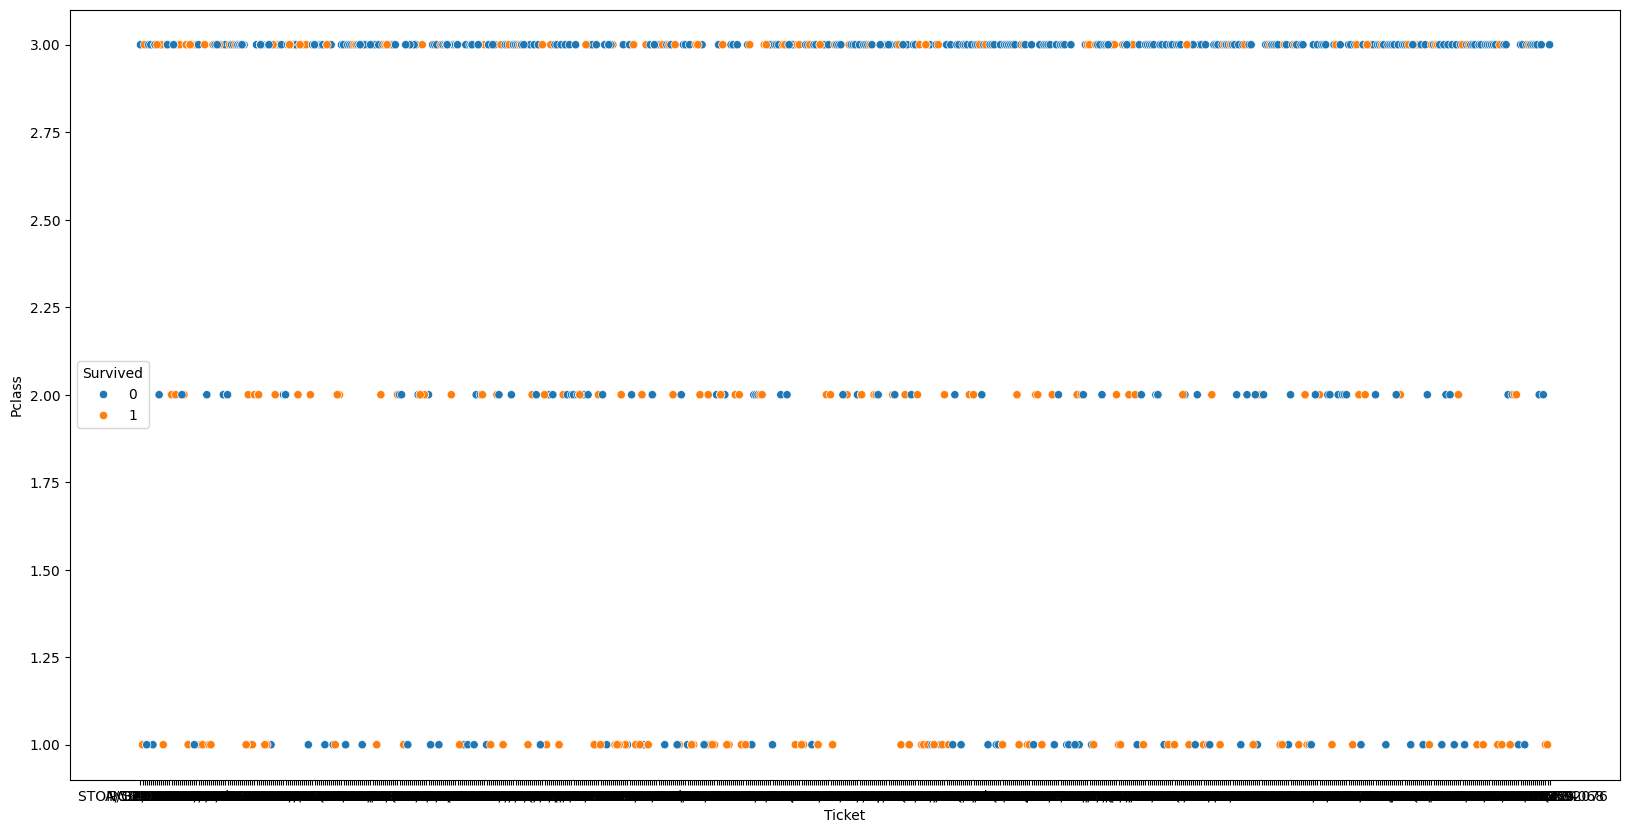

In [22]:
sns.scatterplot(x="Ticket", y="Pclass", hue="Survived", data=df)

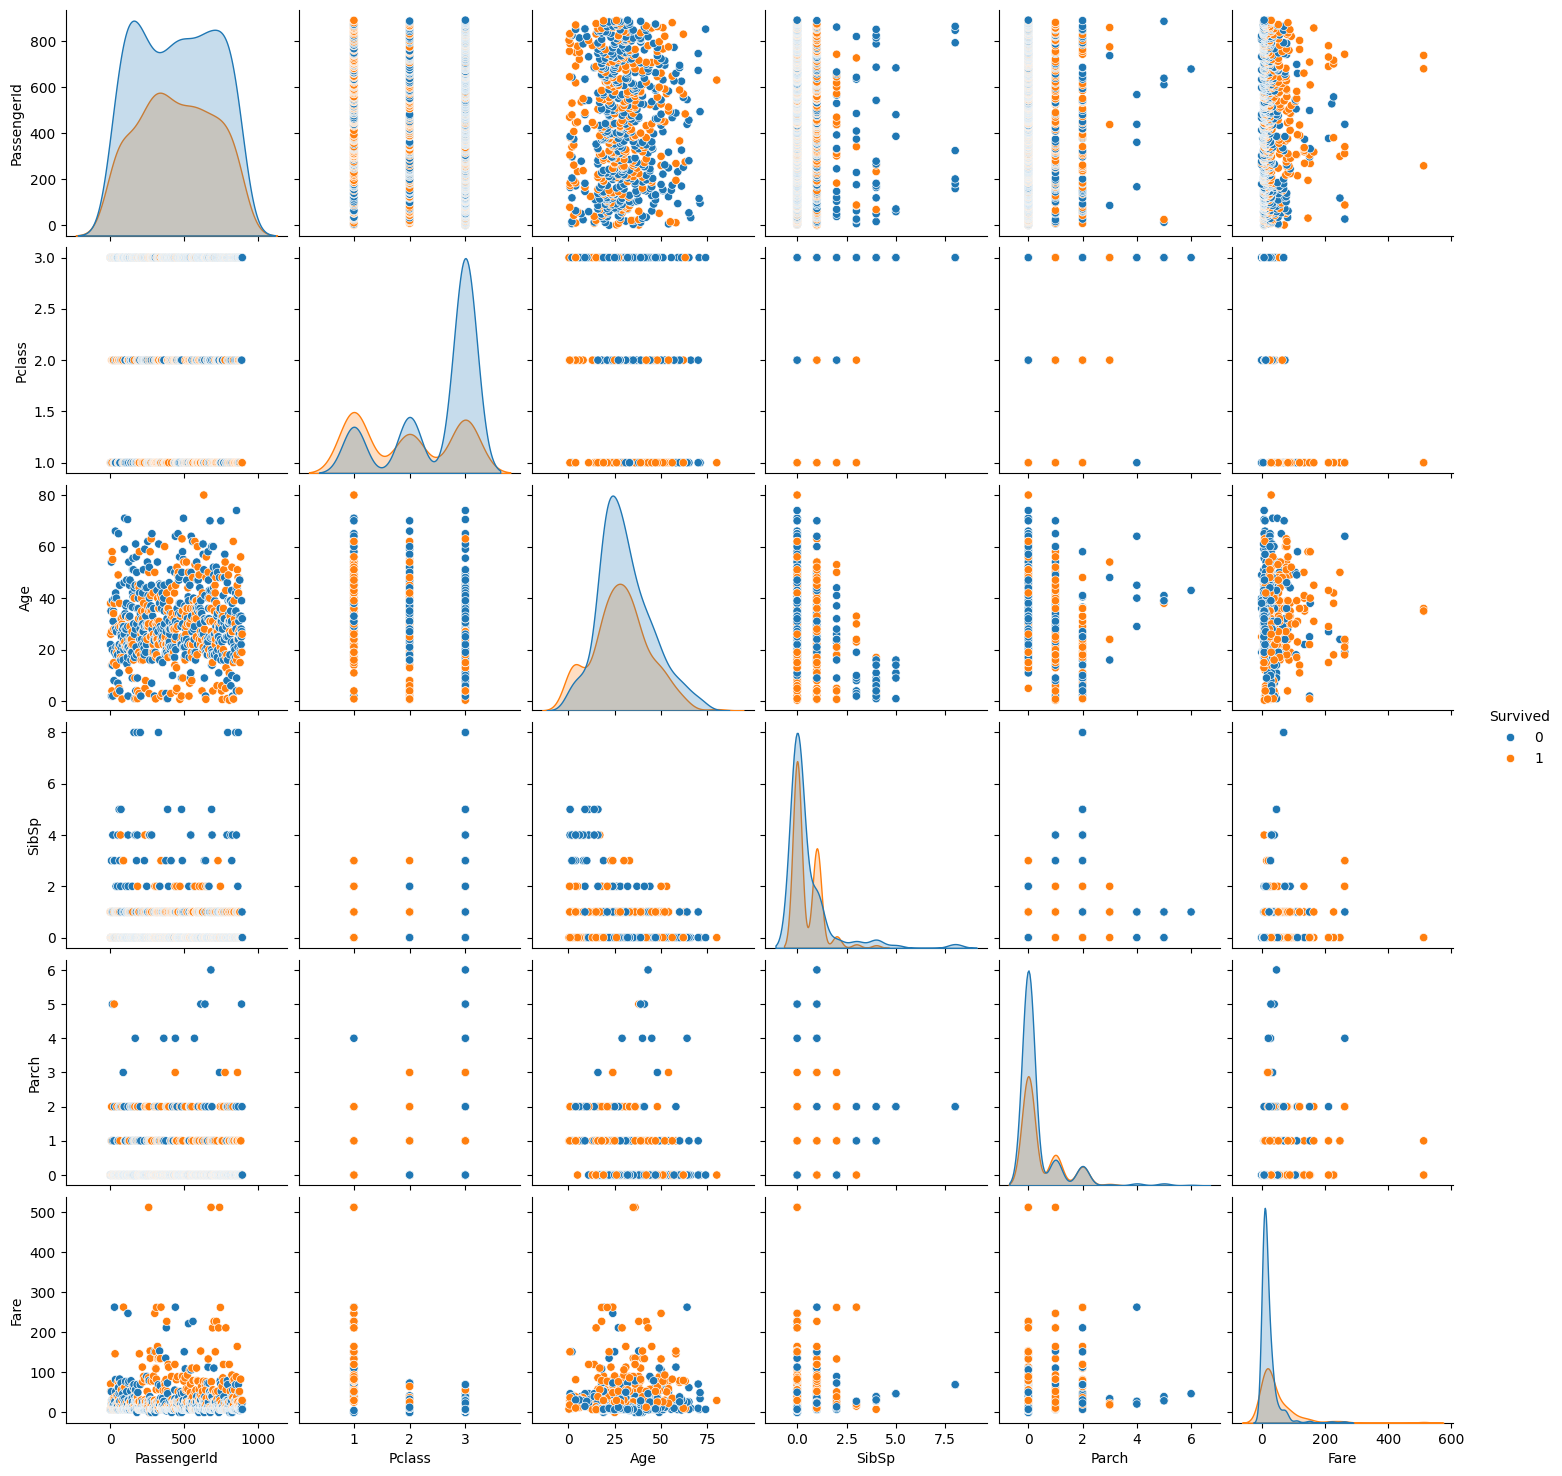

In [23]:
sns.pairplot(df, hue="Survived")

**Insights**<br>

**1. The Strong Influence of Class (Pclass)**<br>
Clear Stratification: Looking at the Pclass histograms and scatter plots, we see a clear separation. First-class passengers (Pclass = 1) have a significantly higher density of survival (orange) than third-class passengers (Pclass = 3), where non-survival (blue) dominates.
Interaction with Fare: The scatter plot of Fare vs. Pclass shows that the highest fares are exclusively in first class, and almost all passengers who paid extremely high fares (the outliers on the far right of the Fare axis) survived.<br>
**2. Age Distributions and Survival**<br>
Youngest Passengers: The diagonal kernel density estimate (KDE) plot for Age shows a distinct peak of survival (orange) at the very low end (infants and young children). This aligns with the historical "women and children first" protocol.
Working-Age Adults: For passengers between roughly 18 and 40, the blue curve (did not survive) is notably higher than the orange curve, indicating a lower rate of survival in this bracket.<br>
**3. Family Structure (SibSp and Parch)**<br>
The Sweet Spot of Family Size: Passengers with $0$$0$ siblings/spouses (SibSp) or parents/children (Parch) have a massive spike in non-survival (blue).
Moderate Families: Those with small family counts (e.g., $1$$1$ or $2$$2$) show a relatively higher proportion of survival. However, as family sizes get very large (values of $4$$4$ to $8$$8$ on the axes), survival rates drop again, likely because large groups struggled to coordinate and find space together in lifeboats.<br>
**4. Correlation and Redundancy**<br>
Fare vs. Class: There is a clear non-linear relationship where lower class values ($1$$1$) map to higher, wider-spread fares, while class $3$$3$ is squished at the very bottom of the fare scale. This confirms that these two features carry overlapping economic signals for the Decision Tree to exploit.<br>

## 3. Prepare features and target

We impute missing numerical values with the median and missing categorical values with the most frequent category. Categorical variables are one-hot encoded so scikit-learn can use them.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"

X = df[features].copy()
y = df[target].copy()

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 712
Testing records: 179


## 4. Train the Decision Tree

We limit the tree to a depth of 4 so that it remains readable for classroom discussion. This is a teaching choice, not a claim that depth 4 is universally optimal.

- `criterion="gini"`: choose splits that reduce Gini impurity.
- `max_depth=4`: limit the number of decision levels.
- `min_samples_leaf=10`: require at least 10 training records in a leaf.


In [8]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=10,
        random_state=42
    ))
])

model.fit(X_train, y_train)
print("Model trained.")


Model trained.


## 5. Visualize the learned decision tree

Each node shows:
- **Rule:** the split condition
- **gini:** impurity (0 means the node contains only one class)
- **samples:** training records reaching the node
- **value:** counts for class 0 and class 1
- **class:** predicted class at that node

The displayed feature names include the one-hot encoded categories.

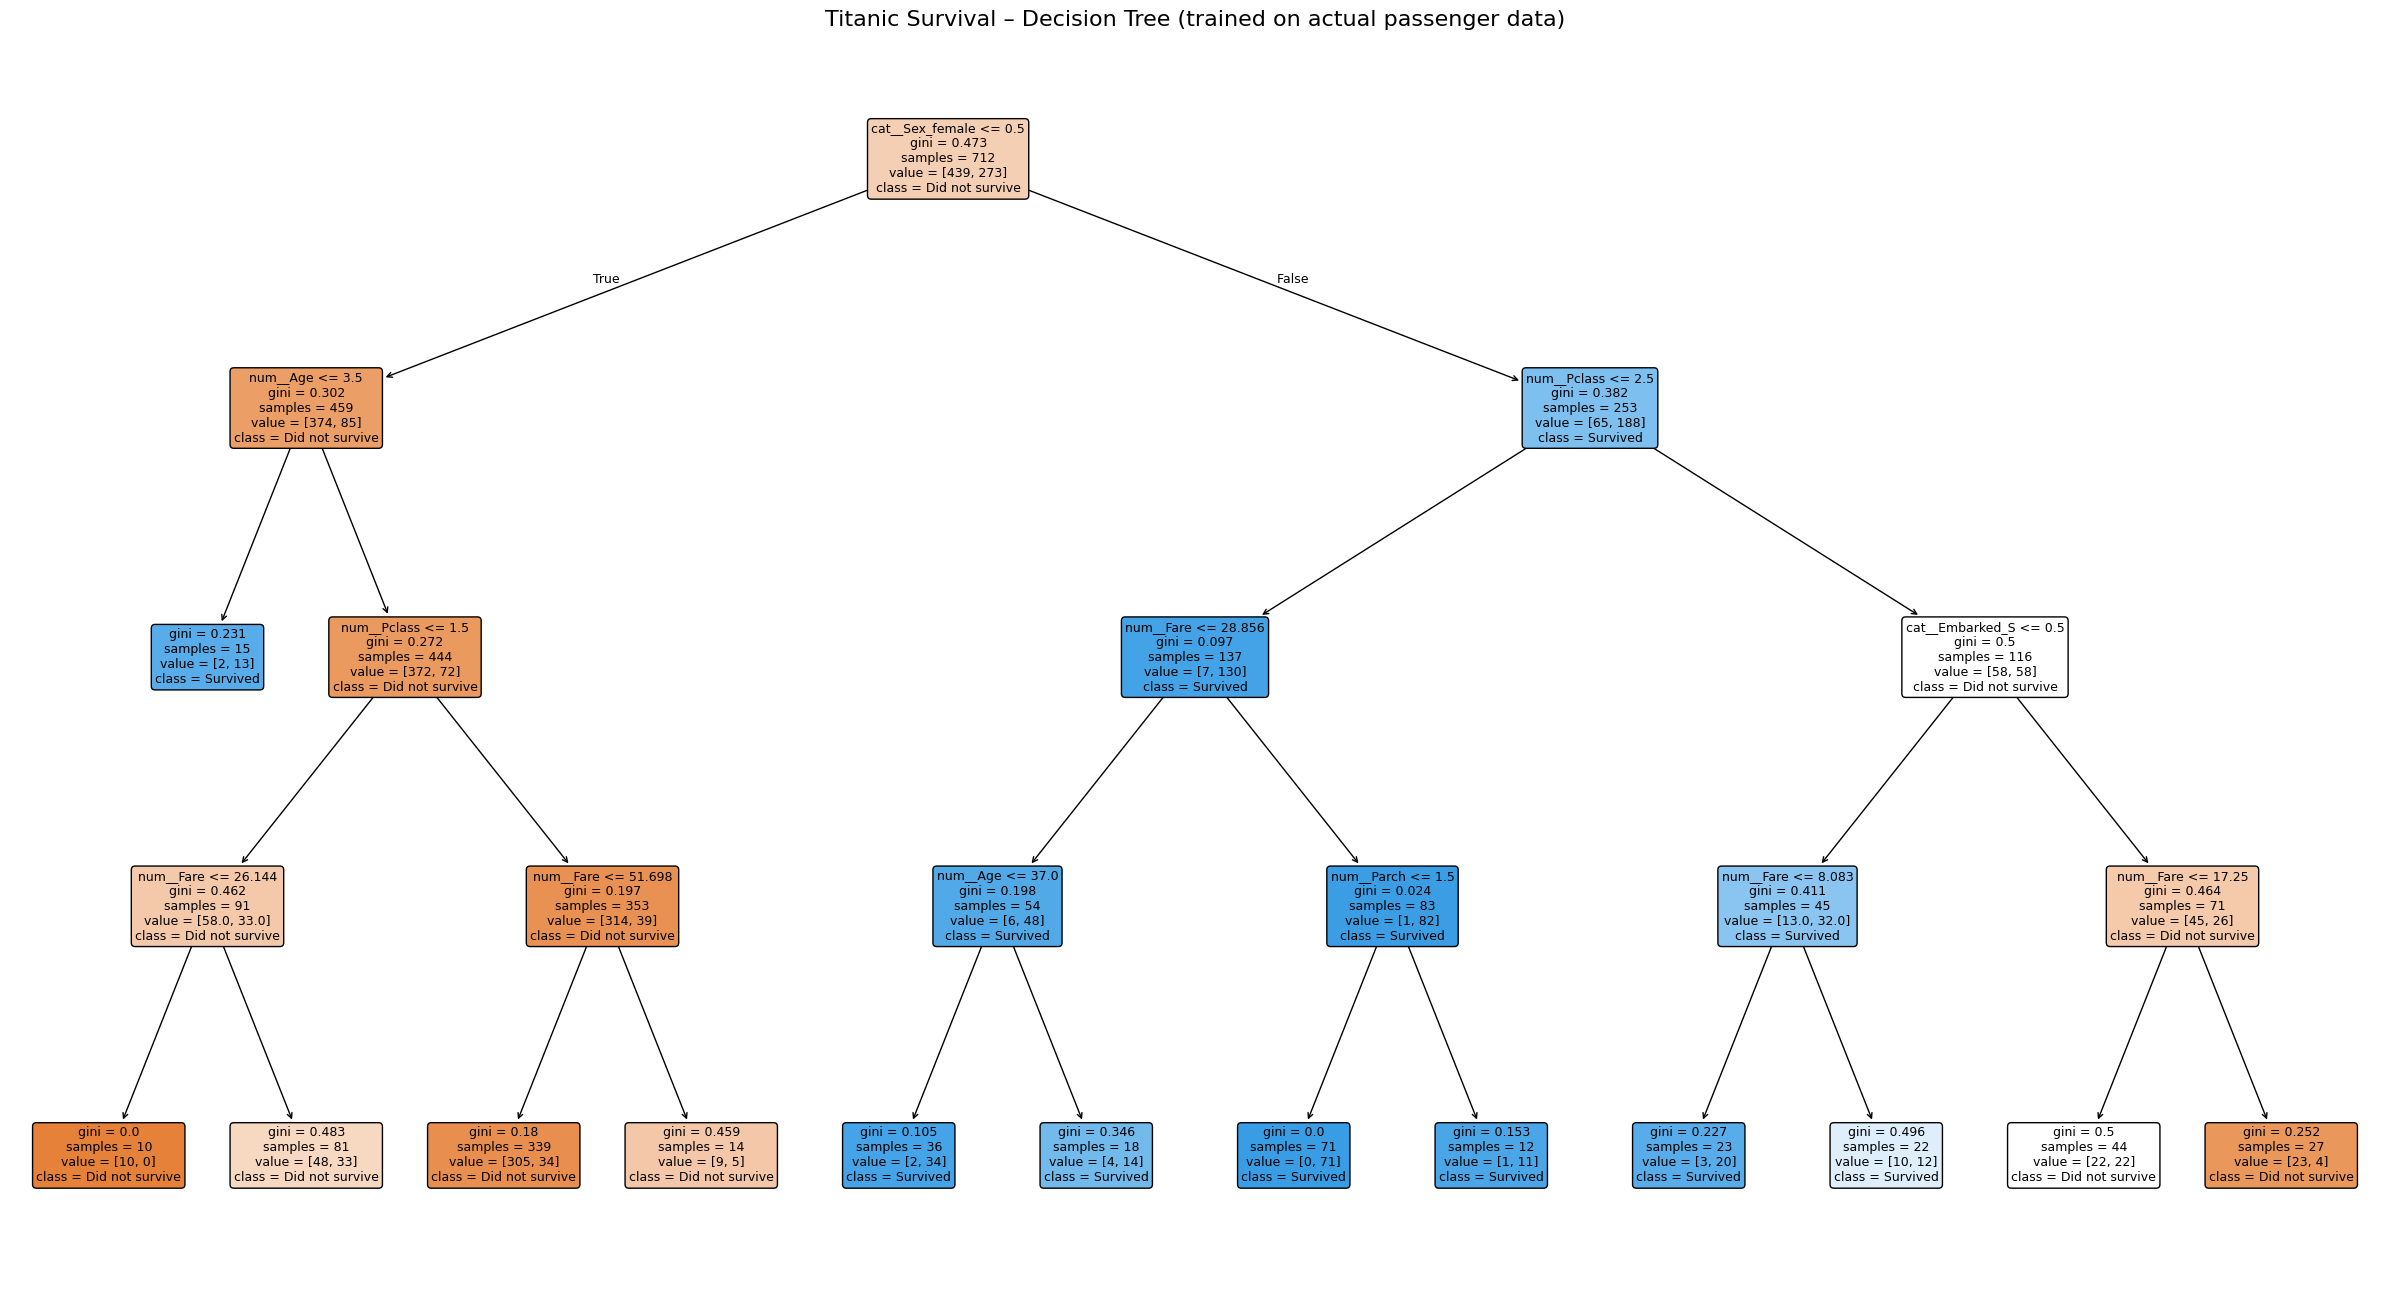

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

preprocessor_fitted = model.named_steps["preprocessor"]
tree_model = model.named_steps["classifier"]
feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(24, 13))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["Did not survive", "Survived"],
    filled=True,
    rounded=True,
    proportion=False,
    impurity=True,
    fontsize=9
)
plt.title("Titanic Survival – Decision Tree (trained on actual passenger data)", fontsize=16)
plt.tight_layout()
plt.show()


## 6. Evaluate the model on unseen test records

Accuracy alone is not enough. We also inspect precision, recall and F1-score for each class, along with the confusion matrix.

Accuracy: 0.777
\nClassification report:
                 precision    recall  f1-score   support

Did not survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179



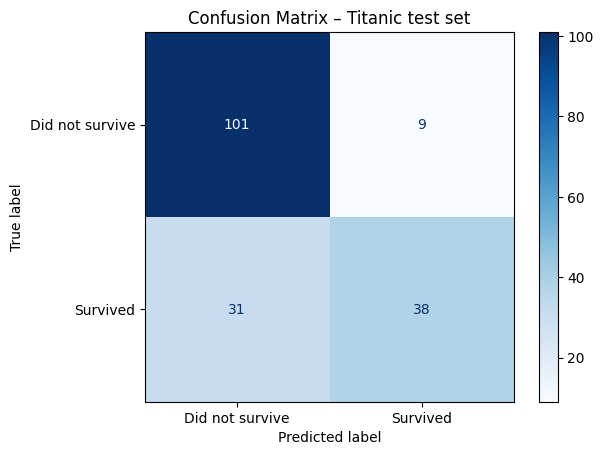

In [10]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy: {:.3f}".format(accuracy_score(y_test, y_pred)))
print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Did not survive", "Survived"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Confusion Matrix – Titanic test set")
plt.show()


## 7. Feature importance

Feature importance measures how much each feature contributed to reducing impurity across the fitted tree. It is useful for explaining the model, but it does **not** prove causation and can be biased toward certain feature types.

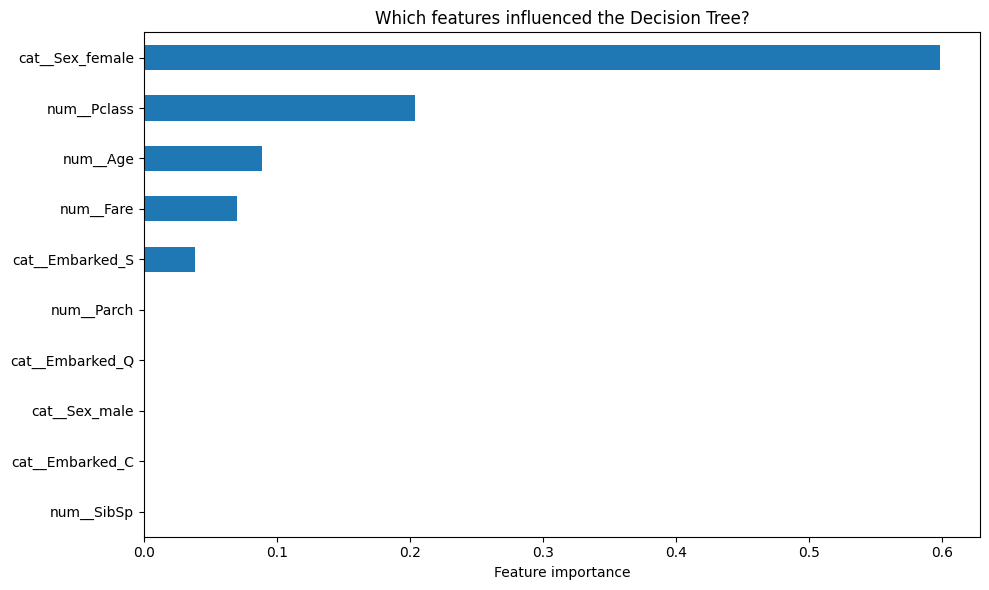

,importance
cat__Sex_female,0.598331
num__Pclass,0.203411
num__Age,0.088809
num__Fare,0.069988
cat__Embarked_S,0.038620
num__Parch,0.000840
cat__Embarked_C,0.000000
num__SibSp,0.000000
cat__Sex_male,0.000000
cat__Embarked_Q,0.000000


In [11]:
importance = pd.Series(
    tree_model.feature_importances_,
    index=feature_names
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Which features influenced the Decision Tree?")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))


## 8. Trace an individual passenger through the tree

Change the values below and observe the predicted class and probability. This is a useful way to explain how a passenger moves from the root node to a leaf.

In [12]:
example_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "male",
    "Age": 22,
    "SibSp": 1,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S"
}])

prediction = model.predict(example_passenger)[0]
probability = model.predict_proba(example_passenger)[0]

print("Predicted outcome:", "Survived" if prediction == 1 else "Did not survive")
print("Probability – did not survive: {:.1%}".format(probability[0]))
print("Probability – survived: {:.1%}".format(probability[1]))


Predicted outcome: Did not survive
Probability – did not survive: 90.0%
Probability – survived: 10.0%


## 9. Classroom discussion

1. Why did the model choose its root split?
2. What does a Gini value of 0 mean?
3. Why do some branches contain many passengers while others contain few?
4. What happens if `max_depth` changes from 4 to 2 or 8?
5. Does a high training accuracy guarantee good performance on unseen passengers?
6. Why should we not interpret feature importance as causation?
7. Which error is more concerning in this example: predicting survival when a passenger did not survive, or predicting non-survival when they survived?

### Experiment

Train three trees with `max_depth` values of 2, 4 and 8. Compare training and test accuracy. Discuss overfitting and generalization.

### Classroom Discussion Answers

#### 1. Why did the model choose its root split?
* **Answer:** The Decision Tree algorithm selects splits by evaluating which feature and threshold best separate the classes (minimizing Gini impurity). In this dataset, gender (`cat__Sex_female <= 0.5`) provides the largest reduction in impurity at the start. Historically, women and children were prioritized during the evacuation, making gender the single most predictive feature of survival.

#### 2. What does a Gini value of 0 mean?
* **Answer:** A Gini impurity of `0` represents a perfectly "pure" node. This means every single training instance that reached this leaf node belongs to the exact same class (either everyone survived or everyone did not survive).

#### 3. Why do some branches contain many passengers while others contain few?
* **Answer:** Tree splitting is based on feature attributes of the sample population. Some combinations of passenger features are very common (e.g., adult males in third class, who represent a large portion of the passenger manifest), resulting in high sample counts in those branches. Conversely, rare combinations (such as young male children in first class with high ticket fares) filter down to branches containing very few passengers.

#### 4. What happens if `max_depth` changes from 4 to 2 or 8?
* **Answer:**
  * **At `max_depth=2`:** The tree is highly simplified (underfitted). It ignores more granular interactions (like age or fare variations) and yields lower accuracy on both training and testing sets.
  * **At `max_depth=8`:** The tree becomes extremely complex and deep (potentially overfitted). It might capture highly specific noise in the training data. As seen in our experiment results, increasing depth to 8 or `None` increases training accuracy but can lead to a drop or plateau in test accuracy.

#### 5. Does a high training accuracy guarantee good performance on unseen passengers?
* **Answer:** No. A high training accuracy only tells us how well the model memorized or fit the data it has already seen. If the tree is too complex, it overfits to noise and patterns unique to the training set, which leads to poor generalization (lower test accuracy) on unseen data.

#### 6. Why should we not interpret feature importance as causation?
* **Answer:** Feature importance in Scikit-Learn simply measures how much a feature's split rules reduced Gini impurity during training. Features can be highly correlated with survival without directly causing it (e.g., having a higher `Fare` didn't save passengers, but purchasing a First Class ticket did, and first-class cabins were physically located closer to the boat deck).

#### 7. Which error is more concerning in this example: predicting survival when a passenger did not survive, or predicting non-survival when they survived?
* **Answer:** This depends on the perspective of the stakeholder:
  * **False Positive (Predicting Survival but they died):** This is highly critical if the model is used for rescue planning, as it might lead to assuming a passenger is safe when they actually need immediate assistance.
  * **False Negative (Predicting Death but they survived):** This causes unnecessary distress to family members or leads search-and-rescue teams to prematurely abandon search efforts for survivors.

In [13]:
# Optional experiment: compare tree depth
from sklearn.base import clone
from sklearn.metrics import accuracy_score

results = []

for depth in [2, 4, 8, None]:
    experiment = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            min_samples_leaf=10,
            random_state=42
        ))
    ])
    experiment.fit(X_train, y_train)
    results.append({
        "max_depth": str(depth),
        "train_accuracy": experiment.score(X_train, y_train),
        "test_accuracy": experiment.score(X_test, y_test)
    })

depth_results = pd.DataFrame(results)
display(depth_results)


,max_depth,train_accuracy,test_accuracy
0,2,0.804775,0.759777
1,4,0.831461,0.776536
2,8,0.867978,0.787709
3,None,0.862360,0.765363
